# Рекомендательная система фильмов

Чернов Илья Дмитриевич, 23п-4

Датасет MovieLens Latest Small. Скачан с GroupLens, на Kaggle это `grouplens/movielens-latest-small`. Ниже данные загружаются, чистятся и на них считаются популярность, коллаборативная фильтрация и рекомендации по жанрам. Потом те же шаги используются в API и окне.

## Загрузка данных

In [1]:
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors

%matplotlib inline

movies = pd.read_csv("ml-latest-small/movies.csv")
ratings = pd.read_csv("ml-latest-small/ratings.csv")
movies.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [2]:
ratings.head()

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [3]:
print("фильмы", movies.shape)
print("оценки", ratings.shape)
ratings["rating"].describe()

фильмы (9742, 3)
оценки (100836, 4)


count    100836.000000
mean          3.501557
std           1.042529
min           0.500000
25%           3.000000
50%           3.500000
75%           4.000000
max           5.000000
Name: rating, dtype: float64

## Обработка данных

Из оценок убирается `timestamp`: для рекомендаций он не нужен. Пустые строки, фильмы без жанра и повторные пары пользователь-фильм тоже выкидываются. Саму оценку оставляем, иначе не из чего строить топ и коллаборативную фильтрацию. Год достается из названия.

In [4]:
print("до чистки", movies.shape, ratings.shape)
print("убираем столбцы", [c for c in ratings.columns if c not in ("userId", "movieId", "rating")])
ratings = ratings.drop(columns=["timestamp"])
movies = movies.dropna(subset=["movieId", "title"]).copy()
ratings = ratings.dropna().copy()
ratings = ratings[ratings["rating"] > 0]
before = len(ratings)
ratings = ratings.groupby(["userId", "movieId"], as_index=False)["rating"].mean()
print("после удаления повторов", len(ratings), "было", before)
movies["title"] = movies["title"].astype(str).str.strip()
movies = movies[movies["title"] != ""]
movies["genres"] = movies["genres"].fillna("")
movies = movies[movies["genres"] != "(no genres listed)"]
movies["year"] = movies["title"].str.extract(r"\((\d{4})\)\s*$")
movies["title_clean"] = movies["title"].apply(lambda x: re.sub(r"[\W_]+", " ", x).strip())
df = ratings.merge(movies, on="movieId")
print("после соединения", df.shape)
df.head()

до чистки (9742, 3) (100836, 4)
убираем столбцы ['timestamp']
после удаления повторов 100836 было 100836
после соединения (100789, 7)


,userId,movieId,rating,title,genres,year,title_clean
0,1,1,4.0,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1995,Toy Story 1995
1,1,3,4.0,Grumpier Old Men (1995),Comedy|Romance,1995,Grumpier Old Men 1995
2,1,6,4.0,Heat (1995),Action|Crime|Thriller,1995,Heat 1995
3,1,47,5.0,Seven (a.k.a. Se7en) (1995),Mystery|Thriller,1995,Seven a k a Se7en 1995
4,1,50,5.0,"Usual Suspects, The (1995)",Crime|Mystery|Thriller,1995,Usual Suspects The 1995


## Популярность

Взвешенный рейтинг, чтобы фильм с парой пятерок не обгонял фильм с сотнями оценок.

`score = (v * R + m * C) / (v + m)`

`v` — число оценок, `R` — средняя, `C` — средняя по всем таким фильмам, `m` — 90-й перцентиль числа оценок. В расчет берутся фильмы минимум с 20 оценками.

In [5]:
pop = df.groupby("movieId").agg(title=("title", "first"), avg=("rating", "mean"), votes=("rating", "count"))
pop = pop[pop["votes"] >= 20].copy()
m = pop["votes"].quantile(0.90)
C = pop["avg"].mean()
pop["score"] = (pop["votes"] * pop["avg"] + m * C) / (pop["votes"] + m)
top10 = pop.sort_values("score", ascending=False).head(10)
print("порог m", round(float(m), 2))
top10

порог m 102.0


,title,avg,votes,score
movieId,,,,
318,"Shawshank Redemption, The (1994)",4.429022,317,4.207943
2959,Fight Club (1999),4.272936,218,4.033212
296,Pulp Fiction (1994),4.197068,307,4.028430
260,Star Wars: Episode IV - A New Hope (1977),4.231076,251,4.025858
858,"Godfather, The (1972)",4.289062,192,4.022544
2571,"Matrix, The (1999)",4.192446,278,4.012179
356,Forrest Gump (1994),4.164134,329,4.011898
527,Schindler's List (1993),4.225000,220,4.001950
50,"Usual Suspects, The (1995)",4.237745,204,3.998784


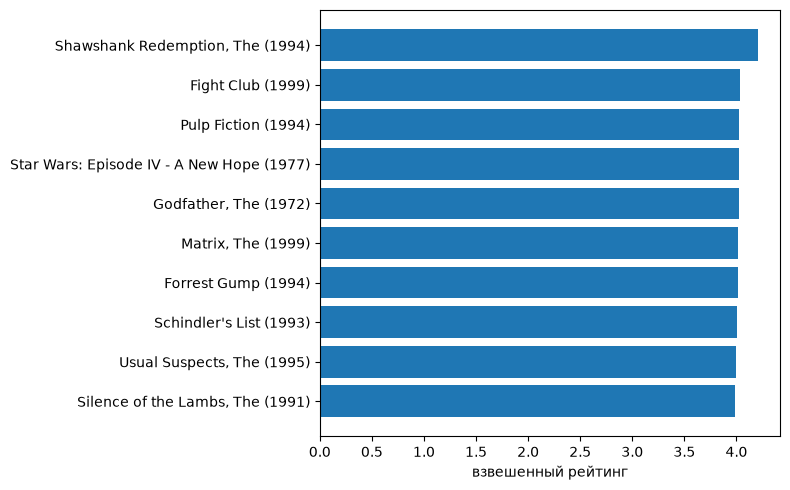

In [6]:
plt.figure(figsize=(8, 5))
plt.barh(top10["title"][::-1], top10["score"][::-1])
plt.xlabel("взвешенный рейтинг")
plt.tight_layout()
plt.show()

## Коллаборативная фильтрация

В модель берутся пользователи, у которых больше 200 оценок, и фильмы, которые такие люди оценили хотя бы 5 раз. Перед сравнением фильмов оценка сдвигается на среднее этого пользователя, иначе в соседи попадают просто популярные картины.

In [7]:
user_cnt = df.groupby("userId").size()
active = user_cnt[user_cnt > 200].index
part = df[df["userId"].isin(active)].copy()
movie_cnt = part.groupby("movieId").size()
part = part[part["movieId"].isin(movie_cnt[movie_cnt >= 5].index)]
print("пользователей", part["userId"].nunique())
print("фильмов", part["movieId"].nunique())
print("оценок", len(part))

user_ids = sorted(part["userId"].unique())
movie_ids = sorted(part["movieId"].unique())
user_index = {user: i for i, user in enumerate(user_ids)}
movie_index = {movie: i for i, movie in enumerate(movie_ids)}
id_to_title = part.drop_duplicates("movieId").set_index("movieId")["title"].to_dict()

rows = part["userId"].map(user_index).to_numpy()
cols = part["movieId"].map(movie_index).to_numpy()
data = part["rating"].to_numpy(dtype=float)
user_item = csr_matrix((data, (rows, cols)), shape=(len(user_ids), len(movie_ids)))

centered = user_item.copy()
for i in range(centered.shape[0]):
    a, b = centered.indptr[i], centered.indptr[i + 1]
    if b > a:
        centered.data[a:b] = centered.data[a:b] - centered.data[a:b].mean()
item_user = centered.T.tocsr()

nn_item = NearestNeighbors(metric="cosine", algorithm="brute")
nn_item.fit(item_user)
nn_user = NearestNeighbors(metric="cosine", algorithm="brute")
nn_user.fit(user_item)

пользователей 133
фильмов 3247
оценок 57804


,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'brute'
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'cosine'
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"radius radius: float, default=1.0Range of parameter space to use by default for :meth:`radius_neighbors`queries.",1.0
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float (positive), default=2Parameter for the Minkowski metric fromsklearn.metrics.pairwise.pairwise_distances. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
Name,Type,Value
effective_metric_ effective_metric_: strMetric used to compute distances to neighbors.,str,'cosine'
effective_metric_params_ effective_metric_params_: dictParameters for the metric used to compute distances to neighbors.,dict,{}


Похожие фильмы. Пример: Toy Story.

In [8]:
def similar_movies(title, n=10):
    found = [mid for mid, name in id_to_title.items() if name == title]
    movie_id = found[0]
    idx = movie_index[movie_id]
    dist, ind = nn_item.kneighbors(item_user.getrow(idx), n_neighbors=n + 1)
    result = []
    for d, j in zip(dist[0], ind[0]):
        mid = movie_ids[int(j)]
        if mid == movie_id:
            continue
        result.append((id_to_title[mid], round(1 - float(d), 3)))
    return result

similar_movies("Toy Story (1995)")

[('Toy Story 2 (1999)', 0.561),
 ('Back to the Future (1985)', 0.485),
 ('Toy Story 3 (2010)', 0.453),
 ('Raiders of the Lost Ark (Indiana Jones and the Raiders of the Lost Ark) (1981)',
  0.433),
 ('Babe (1995)', 0.431),
 ('Star Wars: Episode V - The Empire Strikes Back (1980)', 0.424),
 ('Groundhog Day (1993)', 0.397),
 ('Aladdin (1992)', 0.392),
 ('Star Wars: Episode IV - A New Hope (1977)', 0.391),
 ('Wallace & Gromit: The Wrong Trousers (1993)', 0.389)]

Рекомендации пользователю по похожим людям. Берется первый пользователь из модели.

In [9]:
def recommend_user(user_id, n=10):
    idx = user_index[user_id]
    dist, ind = nn_user.kneighbors(user_item.getrow(idx), n_neighbors=21)
    neigh = ind[0][1:]
    dists = dist[0][1:]
    weights = 1.0 / (dists + 1e-6)
    scores = np.asarray(user_item[neigh].T.dot(weights)).ravel() / weights.sum()
    rated = np.asarray(user_item.getrow(idx).toarray()).ravel()
    scores[rated > 0] = -1
    out = []
    for j in np.argsort(-scores):
        if scores[j] <= 0:
            break
        out.append((id_to_title[movie_ids[int(j)]], round(float(scores[j]), 3)))
        if len(out) >= n:
            break
    return out

print("пользователь", user_ids[0])
recommend_user(user_ids[0])

пользователь 1


[('Terminator 2: Judgment Day (1991)', 4.297),
 ('Sixth Sense, The (1999)', 3.978),
 ('Aliens (1986)', 3.734),
 ("Ferris Bueller's Day Off (1986)", 3.666),
 ('Breakfast Club, The (1985)', 3.664),
 ('Godfather, The (1972)', 3.655),
 ('Jaws (1975)', 3.497),
 ('Die Hard (1988)', 3.428),
 ('Fifth Element, The (1997)', 3.42),
 ('Stand by Me (1986)', 3.41)]

## Рекомендации по контенту

В датасете нет текста сюжета, поэтому сравниваются название и жанры.

In [10]:
meta = part.drop_duplicates("movieId").set_index("movieId")
texts = []
for mid in movie_ids:
    genres = str(meta.loc[mid, "genres"]).replace("|", " ").replace("(no genres listed)", "")
    texts.append(str(meta.loc[mid, "title"]) + " " + genres)

vectorizer = TfidfVectorizer(stop_words="english", max_features=5000)
content_matrix = vectorizer.fit_transform(texts)

def content_like(title, n=10):
    movie_id = [mid for mid, name in id_to_title.items() if name == title][0]
    idx = movie_index[movie_id]
    sims = cosine_similarity(content_matrix[idx], content_matrix).ravel()
    sims[idx] = -1
    out = []
    for j in np.argsort(-sims)[:n]:
        out.append((id_to_title[movie_ids[int(j)]], round(float(sims[j]), 3)))
    return out

content_like("Toy Story (1995)")

[('Toy Story 2 (1999)', 0.884),
 ('Toy Story 3 (2010)', 0.827),
 ('NeverEnding Story, The (1984)', 0.406),
 ('Balto (1995)', 0.363),
 ('L.A. Story (1991)', 0.361),
 ('Jumanji (1995)', 0.353),
 ('Christmas Story, A (1983)', 0.35),
 ('Up (2009)', 0.333),
 ('Shrek the Third (2007)', 0.331),
 ('Monsters, Inc. (2001)', 0.33)]

## Проверка на своих оценках

Если поставить Toy Story оценку 5, похожие фильмы из обученной матрицы поднимаются вверх. В приложении то же самое считается для любого id по его оценкам из базы.

In [11]:
item_sim = cosine_similarity(item_user).astype(np.float32)
vec = np.zeros(len(movie_ids), dtype=np.float32)
vec[movie_index[1]] = 5 - 3
scores = item_sim.dot(vec)
scores[movie_index[1]] = -1e9
personal = []
for j in np.argsort(-scores)[:10]:
    personal.append((id_to_title[movie_ids[int(j)]], round(float(scores[j]), 3)))
personal

[('Toy Story 2 (1999)', 1.122),
 ('Back to the Future (1985)', 0.971),
 ('Toy Story 3 (2010)', 0.907),
 ('Raiders of the Lost Ark (Indiana Jones and the Raiders of the Lost Ark) (1981)',
  0.866),
 ('Babe (1995)', 0.863),
 ('Star Wars: Episode V - The Empire Strikes Back (1980)', 0.848),
 ('Groundhog Day (1993)', 0.794),
 ('Aladdin (1992)', 0.784),
 ('Star Wars: Episode IV - A New Hope (1977)', 0.782),
 ('Wallace & Gromit: The Wrong Trousers (1993)', 0.777)]

## Загрузка в SQLite

Очищенные таблицы пишутся в `movies.db`. Карточка фильма отдельно, оценки отдельно. API и окно читают уже эту базу.

In [12]:
import sqlite3

movies_sql = movies[["movieId", "title", "genres"]].copy()
movies_sql["year"] = movies["title"].str.extract(r"\((\d{4})\)\s*$", expand=False).fillna("")
movies_sql = movies_sql.rename(columns={"movieId": "movie_id"})
movies_sql = movies_sql.drop_duplicates("movie_id")

ratings_sql = df.groupby(["userId", "movieId"], as_index=False)["rating"].mean()
ratings_sql = ratings_sql.rename(columns={"userId": "user_id", "movieId": "movie_id"})

conn = sqlite3.connect("movies.db")
conn.execute("DROP TABLE IF EXISTS ratings")
conn.execute("DROP TABLE IF EXISTS movies")
conn.execute("DROP TABLE IF EXISTS meta")
conn.execute(
    """
CREATE TABLE movies (
    movie_id INTEGER PRIMARY KEY,
    title TEXT,
    genres TEXT,
    year TEXT
)
"""
)
conn.execute(
    """
CREATE TABLE ratings (
    user_id INTEGER,
    movie_id INTEGER,
    rating REAL,
    PRIMARY KEY (user_id, movie_id)
)
"""
)
conn.execute("CREATE TABLE meta (key TEXT PRIMARY KEY, value TEXT)")
conn.executemany(
    "INSERT INTO movies(movie_id, title, genres, year) VALUES (?,?,?,?)",
    list(zip(movies_sql["movie_id"], movies_sql["title"], movies_sql["genres"], movies_sql["year"])),
)
conn.executemany(
    "INSERT INTO ratings(user_id, movie_id, rating) VALUES (?,?,?)",
    list(zip(ratings_sql["user_id"], ratings_sql["movie_id"], ratings_sql["rating"])),
)
conn.execute("CREATE INDEX IF NOT EXISTS idx_movies_title ON movies(title)")
conn.execute("CREATE INDEX IF NOT EXISTS idx_ratings_user ON ratings(user_id)")
conn.execute("INSERT INTO meta(key, value) VALUES ('loaded', '1')")
conn.commit()
print("фильмов в базе", conn.execute("select count(*) from movies").fetchone()[0])
print("оценок в базе", conn.execute("select count(*) from ratings").fetchone()[0])
conn.close()


фильмов в базе 9708
оценок в базе 100789
